# Impact of Transformations in Modeling and Forecasting with ARIMA

**Course:** CSE 4105: Data Science and Applications  
**Department of Computer Science and Engineering, BAUET**  
**Student ID:** 23

### Dataset selection

The assignment selects the series with `ID_last_two_digits %% 6`:

| Student ID | 23 %% 6 | Series |
|---|---|---|
| 23 | **5** | **`UKDriverDeaths`** |

| Item | Value |
|---|---|
| Series | Monthly number of drivers killed or seriously injured in the UK |
| Period | January 1969 - December 1984 |
| Observations | 192 |
| Seasonal period | $s = 12$ (monthly) |
| Split | 70 % training (134 observations) / 30 % test (58 observations) |


### Notation

Backshift operator: $B\,y_t=y_{t-1}$, $B^k y_t=y_{t-k}$, $(1-B)y_t=y_t-y_{t-1}$.

$$\text{ARIMA}(p,d,q):\quad \phi(B)(1-B)^d y_t=c+\theta(B)\varepsilon_t$$

$$\phi(B)=1-\phi_1B-\cdots-\phi_pB^p,\qquad \theta(B)=1+\theta_1B+\cdots+\theta_qB^q$$

$$\text{SARIMA}(p,d,q)(P,D,Q)_s:\quad
\Phi_P(B^s)\phi_p(B)(1-B)^d(1-B^s)^D y_t=c+\Theta_Q(B^s)\theta_q(B)\varepsilon_t$$

$$\Phi_P(B^s)=1-\Phi_1B^s-\cdots-\Phi_PB^{Ps},\qquad
\Theta_Q(B^s)=1+\Theta_1B^s+\cdots+\Theta_QB^{Qs}$$

with $\varepsilon_t\sim WN(0,\sigma^2)$. SARIMA with $P=D=Q=0$ reduces exactly to ARIMA.


In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

S = 12
ALPHA = 0.05
TRAIN_SHARE = 0.70
DATA_FILE = "data/UKDriverDeaths.csv"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.autolayout": True,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
        "font.size": 9,
    }
)


### ACF and PACF

$$\rho_k=\frac{\gamma_k}{\gamma_0}=\frac{\operatorname{Cov}(y_t,y_{t-k})}{\operatorname{Var}(y_t)},
\qquad
r_k=\frac{\sum_{t=k+1}^{T}(y_t-\bar y)(y_{t-k}-\bar y)}{\sum_{t=1}^{T}(y_t-\bar y)^2}$$

$$\phi_{kk}=\frac{\rho_k-\sum_{j=1}^{k-1}\phi_{k-1,j}\,\rho_{k-j}}
{1-\sum_{j=1}^{k-1}\phi_{k-1,j}\,\rho_j}\qquad\text{(Durbin-Levinson)}$$

The significance band is $\pm 1.96/\sqrt{T}$.

In [2]:
def norm_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


def norm_ppf(p):
    a = [
        -3.969683028665376e01,
        2.209460984245205e02,
        -2.759285104469687e02,
        1.383577518672690e02,
        -3.066479806614716e01,
        2.506628277459239e00,
    ]
    b = [
        -5.447609879822406e01,
        1.615858368580409e02,
        -1.556989798598866e02,
        6.680131188771972e01,
        -1.328068155288572e01,
    ]
    c = [
        -7.784894002430293e-03,
        -3.223964580411365e-01,
        -2.400758277161838e00,
        -2.549732539343734e00,
        4.374664141464968e00,
        2.938163982698783e00,
    ]
    d = [
        7.784695709041462e-03,
        3.224671290700398e-01,
        2.445134137142996e00,
        3.754408661907416e00,
    ]
    low, high = 0.02425, 1 - 0.02425
    if p < low:
        q = math.sqrt(-2 * math.log(p))
        return (((((c[0] * q + c[1]) * q + c[2]) * q + c[3]) * q + c[4]) * q + c[5]) / (
            (((d[0] * q + d[1]) * q + d[2]) * q + d[3]) * q + 1
        )
    if p > high:
        q = math.sqrt(-2 * math.log(1 - p))
        return -(
            ((((c[0] * q + c[1]) * q + c[2]) * q + c[3]) * q + c[4]) * q + c[5]
        ) / ((((d[0] * q + d[1]) * q + d[2]) * q + d[3]) * q + 1)
    q = p - 0.5
    r = q * q
    return (
        (((((a[0] * r + a[1]) * r + a[2]) * r + a[3]) * r + a[4]) * r + a[5])
        * q
        / (((((b[0] * r + b[1]) * r + b[2]) * r + b[3]) * r + b[4]) * r + 1)
    )


def chi2_sf(x, df):
    if x <= 0:
        return 1.0
    a, xx = df / 2.0, x / 2.0
    gln = math.lgamma(a)
    if xx < a + 1.0:
        ap, s, term = a, 1.0 / a, 1.0 / a
        for _ in range(400):
            ap += 1.0
            term *= xx / ap
            s += term
            if abs(term) < abs(s) * 1e-14:
                break
        return 1.0 - s * math.exp(-xx + a * math.log(xx) - gln)
    b = xx + 1.0 - a
    c = 1e300
    d = 1.0 / b
    h = d
    for i in range(1, 400):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        d = 1e-300 if abs(d) < 1e-300 else d
        c = b + an / c
        c = 1e-300 if abs(c) < 1e-300 else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < 1e-14:
            break
    return h * math.exp(-xx + a * math.log(xx) - gln)


def acf(x, nlags):
    x = np.asarray(x, float)
    x = x - x.mean()
    denom = x @ x
    return np.array(
        [1.0] + [np.sum(x[k:] * x[:-k]) / denom for k in range(1, nlags + 1)]
    )


def pacf(x, nlags):
    r = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    phi[1, 1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - sum(phi[k - 1, j] * r[k - j] for j in range(1, k))
        den = 1.0 - sum(phi[k - 1, j] * r[j] for j in range(1, k))
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
    return np.array([1.0] + [phi[k, k] for k in range(1, nlags + 1)])


def plot_correlogram(x, nlags, ax, title, kind="acf"):
    x = pd.Series(x).dropna()
    r = acf(x.values, nlags) if kind == "acf" else pacf(x.values, nlags)
    band = 1.96 / math.sqrt(len(x))
    ax.bar(range(1, nlags + 1), r[1:], width=0.6, color="#1f4e79")
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(band, color="#c00000", ls="--", lw=0.9)
    ax.axhline(-band, color="#c00000", ls="--", lw=0.9)
    ax.set_xlim(0.3, nlags + 0.7)
    ax.set_title(title)
    ax.set_xlabel("Lag")


## Step 1: Dataset loading

The R distribution stores the series in long format: `time` is a fractional year
($1969.0833$ is February 1969) and `value` is the number of deaths. The loader converts the
fractional year into a monthly index.

In [3]:
raw = pd.read_csv(DATA_FILE)
months = ((raw["time"] - raw["time"].iloc[0]) * 12).round().astype(int)
index = pd.PeriodIndex(
    [pd.Period("1969-01", freq="M") + int(k) for k in months], freq="M"
).to_timestamp(how="start")
y = pd.Series(raw["value"].to_numpy(), index=index, name="deaths").asfreq("MS")

print(f"Observations : {len(y)}  ({y.index[0]:%b %Y} - {y.index[-1]:%b %Y})")
print(f"Frequency    : monthly, s = {S}")
print(f"Min / Max    : {y.min():.0f} / {y.max():.0f}")
print(f"Mean / Median: {y.mean():.1f} / {y.median():.1f}")
print(f"Std. dev.    : {y.std():.1f}")
print(f"Missing      : {int(y.isna().sum())}")
print()
print(y.head().to_string())


Observations : 192  (Jan 1969 - Dec 1984)
Frequency    : monthly, s = 12
Min / Max    : 1057 / 2654
Mean / Median: 1670.3 / 1631.0
Std. dev.    : 289.6
Missing      : 0

1969-01-01    1687
1969-02-01    1508
1969-03-01    1507
1969-04-01    1385
1969-05-01    1632
Freq: MS


## Step 2: Exploratory data analysis

The three plots required by the assignment are the time plot, the sample ACF and the
seasonal subseries plot; the train/test split is shown alongside them.

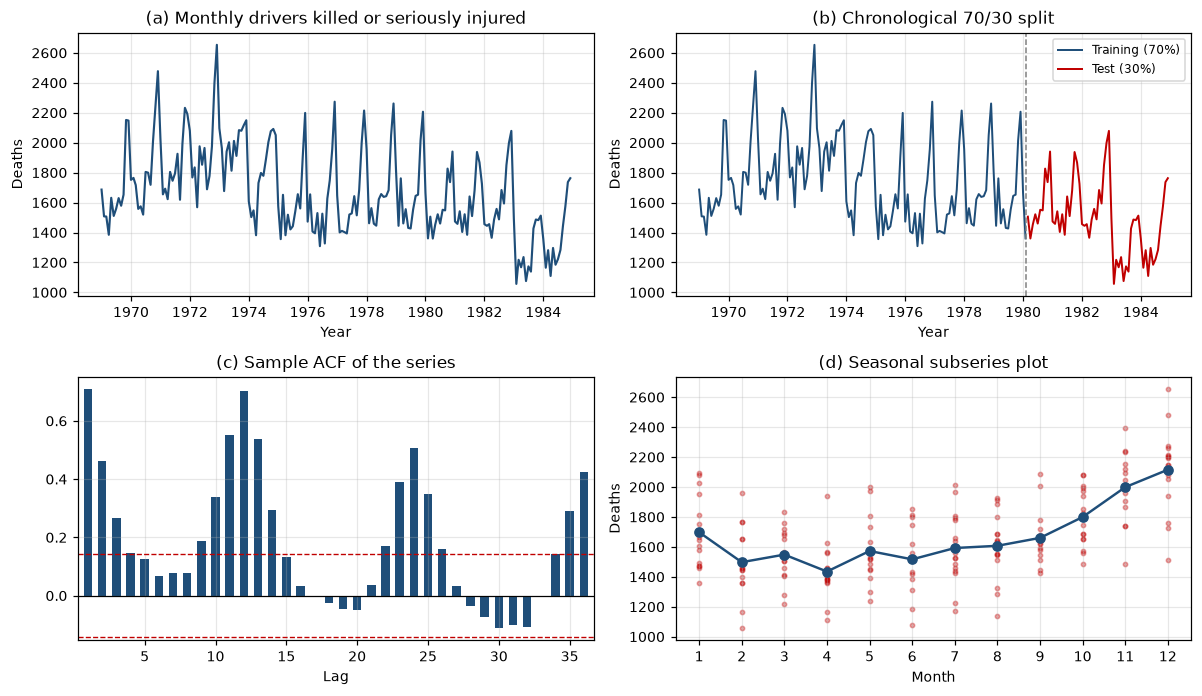

In [4]:
n_train = int(len(y) * TRAIN_SHARE)
train, test = y.iloc[:n_train], y.iloc[n_train:]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))

axes[0, 0].plot(y.index, y, color="#1f4e79", lw=1.4)
axes[0, 0].set_title("(a) Monthly drivers killed or seriously injured")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Deaths")

axes[0, 1].plot(train.index, train, color="#1f4e79", lw=1.3, label="Training (70%)")
axes[0, 1].plot(test.index, test, color="#c00000", lw=1.3, label="Test (30%)")
axes[0, 1].axvline(train.index[-1], color="grey", ls="--", lw=1)
axes[0, 1].set_title("(b) Chronological 70/30 split")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Deaths")
axes[0, 1].legend(loc="upper right", fontsize=8)

plot_correlogram(y, 36, axes[1, 0], "(c) Sample ACF of the series")

monthly_mean = y.groupby(y.index.month).mean()
axes[1, 1].plot(
    monthly_mean.index, monthly_mean.values, marker="o", color="#1f4e79", lw=1.6
)
for m in range(1, 13):
    vals = y[y.index.month == m]
    axes[1, 1].scatter([m] * len(vals), vals, s=8, alpha=0.35, color="#c00000")
axes[1, 1].set_xticks(range(1, 13))
axes[1, 1].set_title("(d) Seasonal subseries plot")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Deaths")
plt.show()


In [5]:
monthly = y.groupby(y.index.month).agg(["mean", "std", "min", "max"]).round(1)
monthly.index.name = "Month"
yearly = y.groupby(y.index.year).mean().round(0)
print("Monthly summary (all 16 years)")
print(monthly.to_string())
print()
print("Yearly mean")
print(yearly.to_string())


Monthly summary (all 16 years)
         mean    std   min   max
Month                           
1      1697.9  236.9  1357  2097
2      1497.9  226.9  1057  1963
3      1548.5  170.4  1218  1835
4      1435.3  187.1  1110  1941
5      1572.6  215.6  1236  2003
6      1516.9  220.1  1076  1853
7      1592.5  237.0  1174  2012
8      1607.4  223.2  1139  1926
9      1660.2  176.0  1427  2084
10     1799.6  194.4  1487  2080
11     1999.1  224.0  1483  2397
12     2115.8  280.0  1513  2654

Yearly mean
1969    1663.0
1970    1828.0
1971    1859.0
1972    1962.0
1973    1988.0
1974    1788.0
1975    1601.0
1976    1602.0
1977    1614.0
1978    1703.0
1979    1664.0
1980    1578.0
1981    1596.0
1982    1622.0
1983    1289.0
1984    1368.0


### Main features of the series

1. **Seasonality.** The seasonal subseries plot and the monthly means show a clear annual
   cycle. Deaths peak in **December** (mean 2 116) and November (1 999) and reach their
   minimum in **April** (1 435), February (1 498) and June (1 517). The average
   December-April gap is about 680 deaths, and the pattern repeats in every year.
2. **Trend and level shifts.** The level is not constant: the yearly mean rises from 1 663
   (1969) to 1 988 (1973), falls sharply to about 1 600 after the 1973 oil crisis, stays
   near 1 600-1 700 until 1982, and then drops to 1 289 in 1983 (-20.5 % versus 1982) after
   the seat-belt law of January 1983.
3. **Variance.** Unlike an exponentially growing series, the spread here does **not**
   increase with the level: the within-month standard deviation is between 170 and 280
   deaths throughout, while the mean moves between 1 435 and 2 116. A variance-stabilising
   transformation is therefore expected to give only a small improvement; this is examined
   in models M2 and M3.
4. **Autocorrelation.** The ACF decays slowly and has a large hump at lag 12; the series is
   trended and strongly seasonal, so it is not stationary. Regular and seasonal
   differencing will be required.
5. **Data quality.** No missing values, 192 monthly observations, 16 complete years. The
   level shifts are genuine interventions and will remain in the residuals of every model.


## Step 3: Data splitting (70 % / 30 %)

The split is chronological: the model is estimated on January 1969 - February 1980 and
evaluated on March 1980 - December 1984. Shuffling would destroy the temporal order and
make the test set useless for forecasting.

In [6]:
print(
    f"Training : n = {len(train)}  ({train.index[0]:%b %Y} - {train.index[-1]:%b %Y})"
)
print(f"Test     : n = {len(test)}  ({test.index[0]:%b %Y} - {test.index[-1]:%b %Y})")
print()
print(
    pd.DataFrame({"train": train.describe(), "test": test.describe()})
    .round(1)
    .to_string()
)


Training : n = 134  (Jan 1969 - Feb 1980)
Test     : n = 58  (Mar 1980 - Dec 1984)

        train    test
count   134.0    58.0
mean   1748.4  1489.8
std     275.4   237.9
min    1309.0  1057.0
25%    1533.2  1357.8
50%    1680.0  1485.0
75%    1964.5  1589.2
max    2654.0  2079.0


## Step 4: Seasonality, stationarity and differencing

**Seasonality test.** The Kruskal-Wallis test compares the twelve monthly samples. It is
distribution-free and tests

$$H_0:\text{the monthly distributions are identical (no seasonality)},\qquad
H_1:\text{at least one month differs}.$$

With $k=12$ groups of sizes $n_j$, pooled size $N=\sum_j n_j$ and average ranks $R_{ij}$,

$$H=\frac{12}{N(N+1)}\sum_{j=1}^{k}\frac{R_j^2}{n_j}-3(N+1)
\;\sim\;\chi^2_{k-1},\qquad R_j=\sum_{i=1}^{n_j}R_{ij},$$

with a correction for ties. If $p<0.05$ the series is seasonal: the seasonal difference
$(1-B^{12})$ is applied ($D=1$) and seasonal AR/MA terms are allowed. Otherwise $D=0$ and
the models are non-seasonal ARIMA. The sample ACF at lag 12 is reported as supporting
evidence.

**ADF test.** The regression

$$\Delta y_t=\alpha+\beta t+\gamma y_{t-1}+\sum_{i=1}^{k}\delta_i\Delta y_{t-i}+\varepsilon_t,
\qquad \tau=\frac{\hat\gamma}{\operatorname{se}(\hat\gamma)}$$

is estimated by ordinary least squares, with $k$ chosen by AIC. $H_0:\gamma=0$ (unit root);
the 5 % critical value is $-2.86$ for a constant-only regression.

**KPSS test.**

$$y_t=\xi t+r_t+\varepsilon_t,\qquad r_t=r_{t-1}+u_t,\qquad
\eta=\frac{1}{T^2\hat\sigma_\ell^2}\sum_{t=1}^{T}S_t^2,\qquad S_t=\sum_{i=1}^{t}\hat e_i$$

with $H_0$ stationarity and the 5 % critical value $0.463$ for level stationarity. The
long-run variance $\hat\sigma_\ell^2=\hat\gamma_0+2\sum_{i=1}^{\ell}\left(1-\frac{i}{\ell+1}\right)\hat\gamma_i$
uses the Newey-West weights and $\ell=4(T/100)^{1/4}$ lags.

ADF and KPSS are complementary: a series is accepted as stationary only when ADF rejects
**and** KPSS does not reject.

In [7]:
def ols(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    s2 = resid @ resid / (len(y) - X.shape[1])
    cov = s2 * np.linalg.pinv(X.T @ X)
    return beta, resid, cov


def adf_tau(x, maxlag=12):
    x = np.asarray(x, float)
    dx = np.diff(x)
    j0 = maxlag
    best = None
    for k in range(maxlag + 1):
        yv = dx[j0:]
        n = len(yv)
        cols = [x[j0 : len(x) - 1]]
        cols += [dx[j0 - i : len(dx) - i] for i in range(1, k + 1)]
        cols += [np.ones(n)]
        X = np.column_stack(cols)
        beta, resid, cov = ols(X, yv)
        ll = -0.5 * n * (math.log(2 * math.pi * (resid @ resid / n)) + 1)
        aic = -2 * ll + 2 * X.shape[1]
        if best is None or aic < best[0]:
            best = (aic, beta[0], math.sqrt(cov[0, 0]))
    return best[1] / best[2]


def kpss_stat(x, lags=None):
    x = np.asarray(x, float)
    T = len(x)
    e = x - x.mean()
    St = np.cumsum(e)
    if lags is None:
        lags = int(4 * (T / 100) ** 0.25)
    lrv = e @ e / T
    for l in range(1, lags + 1):
        lrv += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / T
    return St @ St / (T**2 * lrv)


def difference(x, d=1, D=0, s=S):
    z = np.asarray(x, float)
    if d:
        z = np.diff(z, n=d)
    if D:
        z = z[s * D :] - z[: -s * D]
    return z


def ljung_box(e, h, fitdf=0):
    e = np.asarray(e, float)
    r = acf(e, h)[1:]
    T = len(e)
    Q = T * (T + 2) * np.sum(r**2 / (T - np.arange(1, h + 1)))
    return Q, chi2_sf(Q, h - fitdf)


def jarque_bera(e):
    e = np.asarray(e, float)
    n = len(e)
    m2 = np.mean((e - e.mean()) ** 2)
    sk = np.mean((e - e.mean()) ** 3) / m2**1.5
    ku = np.mean((e - e.mean()) ** 4) / m2**2
    stat = n / 6 * (sk**2 + (ku - 3) ** 2 / 4)
    return stat, chi2_sf(stat, 2)


def arch_lm(e, q=12):
    e = np.asarray(e, float) ** 2
    yv = e[q:]
    X = np.column_stack(
        [np.ones(len(yv))] + [e[q - i : len(e) - i] for i in range(1, q + 1)]
    )
    _, resid, _ = ols(X, yv)
    r2 = 1 - (resid @ resid) / np.sum((yv - yv.mean()) ** 2)
    stat = len(yv) * r2
    return stat, chi2_sf(stat, q)


def kruskal_wallis(groups):
    groups = [np.asarray(g, float) for g in groups]
    pooled = np.concatenate(groups)
    n = len(pooled)
    ranks = pd.Series(pooled).rank().to_numpy()
    pos, total = 0, 0.0
    for g in groups:
        r = ranks[pos : pos + len(g)]
        total += r.sum() ** 2 / len(g)
        pos += len(g)
    stat = 12.0 / (n * (n + 1)) * total - 3 * (n + 1)
    _, counts = np.unique(pooled, return_counts=True)
    ties = np.sum(counts**3 - counts)
    stat = stat / (1 - ties / (n**3 - n)) if ties else stat
    return stat, chi2_sf(stat, len(groups) - 1)


In [8]:
groups = [train[train.index.month == m].values for m in range(1, 13)]
h_kw, p_kw = kruskal_wallis(groups)
SEASONAL = p_kw < ALPHA
D_ORDER = 1 if SEASONAL else 0
QS = 1 if SEASONAL else 0

print(f"Kruskal-Wallis: H = {h_kw:.3f}, p = {p_kw:.3e}")
print(
    f"Decision: the series is {'seasonal' if SEASONAL else 'non-seasonal'} "
    f"-> D = {D_ORDER}, seasonal AR/MA terms {'allowed' if SEASONAL else 'not used'}"
)
print()

r_y = acf(train.values, 36)
band = 1.96 / math.sqrt(len(train))
print(
    f"Supporting ACF: r12 = {r_y[12]:.3f}, r24 = {r_y[24]:.3f}, "
    f"r36 = {r_y[36]:.3f}, band = +/- {band:.3f}"
)

trials = [("y_t", train.values), ("(1-B) y_t", difference(train.values, 1, 0))]
if SEASONAL:
    trials += [
        ("(1-B^12) y_t", difference(train.values, 0, 1)),
        ("(1-B)(1-B^12) y_t", difference(train.values, 1, 1)),
    ]

rows = []
for label, x in trials:
    tau, eta = adf_tau(x), kpss_stat(x)
    adf_stationary, kpss_stationary = tau < -2.86, eta < 0.463
    verdict = (
        "stationary"
        if adf_stationary and kpss_stationary
        else (
            "non-stationary"
            if not adf_stationary and not kpss_stationary
            else "conflict"
        )
    )
    rows.append(
        {
            "Series": label,
            "n": len(x),
            "ADF tau": round(tau, 3),
            "KPSS": round(eta, 3),
            "ADF says": "stationary" if adf_stationary else "unit root",
            "KPSS says": "stationary" if kpss_stationary else "non-stationary",
            "Conclusion": verdict,
        }
    )
pd.DataFrame(rows).set_index("Series").round(3)


Kruskal-Wallis: H = 68.239, p = 2.637e-10
Decision: the series is seasonal -> D = 1, seasonal AR/MA terms allowed

Supporting ACF: r12 = 0.691, r24 = 0.492, r36 = 0.356, band = +/- 0.169


,n,ADF tau,KPSS,ADF says,KPSS says,Conclusion
Series,,,,,,
y_t,134,-0.858,0.472,unit root,non-stationary,non-stationary
(1-B) y_t,133,-3.886,0.029,stationary,stationary,stationary
(1-B^12) y_t,122,-2.521,0.366,unit root,stationary,conflict
(1-B)(1-B^12) y_t,121,-4.464,0.028,stationary,stationary,stationary


**Reading.** The Kruskal-Wallis statistic is $H=68.24$ with $p=2.6\times10^{-10}$, so the
null of identical monthly distributions is rejected: the series is seasonal. The sample ACF
confirms this ($r_{12}=0.691$, far outside the $\pm0.169$ band), so $D=1$ and seasonal
AR/MA terms are allowed in every model.

The raw series is non-stationary under both tests ($\tau=-0.858>-2.86$ and
$\eta=0.472>0.463$). One regular difference is stationary under both tests, but the ACF of
$(1-B)y_t$ still has a seasonal spike at lag 12 ($0.537$ against a band of $0.171$), so the
seasonal pattern is not removed. Taking the seasonal difference as well gives
$(1-B)(1-B^{12})y_t$, which is stationary under both tests ($\tau=-4.464$, $\eta=0.028$).

Hence $d=1$ and $D=1$ for every model. If the Kruskal-Wallis test had been non-significant,
the code would set $D=0$ and $P=Q=0$, and only the regular difference would be applied
before fitting non-seasonal ARIMA models.

### Autocorrelation of the differenced series

The ACF and PACF of $(1-B)(1-B^{12})y_t$ are plotted below.

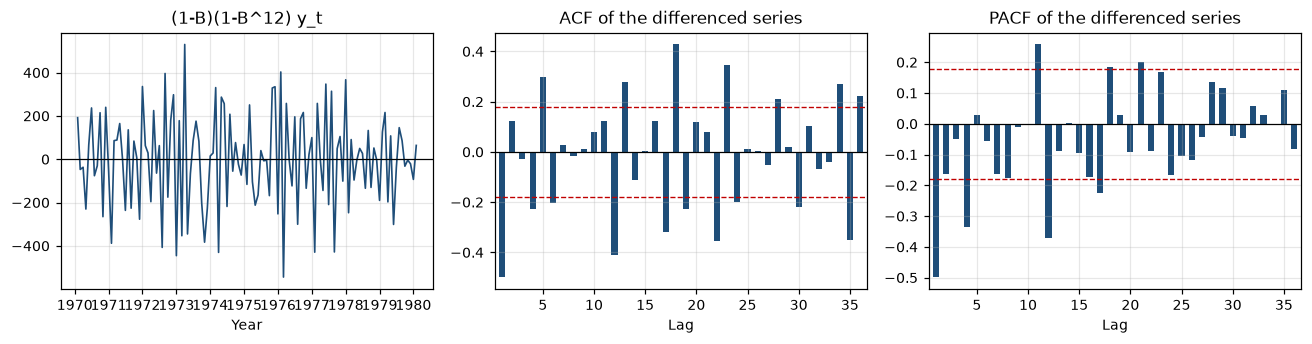

white-noise band: +/- 0.178 (n = 121)
significant ACF lags : [(1, -0.5), (4, -0.23), (5, 0.3), (6, -0.2), (12, -0.41), (13, 0.28), (17, -0.32), (18, 0.43), (19, -0.23), (22, -0.35), (23, 0.35), (24, -0.2), (28, 0.21), (30, -0.22), (34, 0.27), (35, -0.35), (36, 0.22)]
significant PACF lags: [(1, -0.5), (4, -0.34), (11, 0.26), (12, -0.37), (17, -0.22), (18, 0.18), (21, 0.2)]


In [9]:
z = difference(train.values, 1, D_ORDER)
z_index = train.index[-len(z) :]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(z_index, z, color="#1f4e79", lw=1.1)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("(1-B)(1-B^12) y_t" if SEASONAL else "(1-B) y_t")
axes[0].set_xlabel("Year")

plot_correlogram(z, 36, axes[1], "ACF of the differenced series")
plot_correlogram(z, 36, axes[2], "PACF of the differenced series", kind="pacf")
plt.show()

bound = 1.96 / math.sqrt(len(z))
a, p = acf(z, 36), pacf(z, 36)
print(f"white-noise band: +/- {bound:.3f} (n = {len(z)})")
print(
    "significant ACF lags :",
    [(i, round(a[i], 2)) for i in range(1, 37) if abs(a[i]) > bound],
)
print(
    "significant PACF lags:",
    [(i, round(p[i], 2)) for i in range(1, 37) if abs(p[i]) > bound],
)


## Step 5: Orders from the ACF and PACF

The dominant autocorrelations of $(1-B)(1-B^{12})y_t$ are at lag 1 ($-0.50$) and at the
seasonal lag 12 ($-0.41$), with a decaying echo at lags 13, 23 and 24. Both the ACF and the
PACF have their first large spike at lag 1, which is the signature of a mixed ARMA(1,1)
structure, and the seasonal spike at lag 12 points to a seasonal MA(1) term.

The candidate model is therefore

$$\text{M1 candidate}:\quad (1-B)(1-B^{12})y_t=(1+\theta_1B)(1+\Theta_1B^{12})\varepsilon_t,$$

and, when the residual diagnostics require an additional AR term,

$$\text{M1}:\quad (1-\phi_1B)(1-B)(1-B^{12})y_t=(1+\theta_1B)(1+\Theta_1B^{12})\varepsilon_t.$$

The models are estimated by conditional sum of squares: for the differenced series $z_t$,
the residuals follow from

$$z_t=\phi_1 z_{t-1}+\Phi_1 z_{t-12}-\phi_1\Phi_1 z_{t-13}
+\varepsilon_t+\theta_1\varepsilon_{t-1}+\Theta_1\varepsilon_{t-12}+\theta_1\Theta_1\varepsilon_{t-13},$$

and the parameter vector minimises $\sum_t\varepsilon_t^2$. With $\hat\sigma^2=\sum\hat\varepsilon_t^2/n$
the Gaussian likelihood is

$$\ln\hat L=-\frac{n}{2}\left[\ln(2\pi\hat\sigma^2)+1\right].$$

In [10]:
def nelder_mead(f, x0, step=0.2, tol=1e-8, maxiter=4000):
    x0 = np.asarray(x0, float)
    n = len(x0)
    if n == 0:
        return x0, f(x0)
    simplex = [x0.copy()]
    for i in range(n):
        p = x0.copy()
        p[i] += step
        simplex.append(p)
    vals = [f(p) for p in simplex]
    for _ in range(maxiter):
        order = np.argsort(vals)
        simplex = [simplex[i] for i in order]
        vals = [vals[i] for i in order]
        if abs(vals[-1] - vals[0]) < tol * (abs(vals[0]) + 1e-12):
            break
        centroid = np.mean(simplex[:-1], axis=0)
        xr = centroid + (centroid - simplex[-1])
        fr = f(xr)
        if fr < vals[0]:
            xe = centroid + 2 * (centroid - simplex[-1])
            fe = f(xe)
            simplex[-1], vals[-1] = (xe, fe) if fe < fr else (xr, fr)
        elif fr < vals[-2]:
            simplex[-1], vals[-1] = xr, fr
        else:
            xc = centroid + 0.5 * (simplex[-1] - centroid)
            fc = f(xc)
            if fc < vals[-1]:
                simplex[-1], vals[-1] = xc, fc
            else:
                for i in range(1, n + 1):
                    simplex[i] = simplex[0] + 0.5 * (simplex[i] - simplex[0])
                    vals[i] = f(simplex[i])
    i = int(np.argmin(vals))
    return simplex[i], vals[i]


def expand(u, p, q, P, Q, s):
    th = 0.95 * np.tanh(u)
    phi = th[:p]
    theta = th[p : p + q]
    Phi = th[p + q : p + q + P]
    Theta = th[p + q + P : p + q + P + Q]
    ar = np.r_[1.0, -phi]
    ar_s = np.zeros(P * s + 1)
    ar_s[0] = 1.0
    for j in range(1, P + 1):
        ar_s[j * s] = -Phi[j - 1]
    ma = np.r_[1.0, theta]
    ma_s = np.zeros(Q * s + 1)
    ma_s[0] = 1.0
    for j in range(1, Q + 1):
        ma_s[j * s] = Theta[j - 1]
    return np.convolve(ar, ar_s), np.convolve(ma, ma_s)


def residuals(z, ar_poly, ma_poly):
    p_, q_ = len(ar_poly) - 1, len(ma_poly) - 1
    start = max(p_, q_)
    eps = np.zeros(len(z))
    for t in range(start, len(z)):
        ar_part = ar_poly[1:] @ z[t - p_ : t][::-1] if p_ else 0.0
        ma_part = ma_poly[1:] @ eps[t - q_ : t][::-1] if q_ else 0.0
        eps[t] = z[t] - ar_part - ma_part
    return eps, start


def roots_outside(poly):
    poly = np.asarray(poly, float)
    if len(poly) <= 1 or not np.any(poly[1:]):
        return True
    roots = np.roots(poly[::-1])
    return roots.size == 0 or np.min(np.abs(roots)) > 1.0


def fit_sarima(y, order, seasonal):
    p, d, q = order
    P, D, Q, s = seasonal
    z = difference(y, d, D, s)
    n = len(z)

    def sse(u):
        ar_poly, ma_poly = expand(u, p, q, P, Q, s)
        if not roots_outside(ar_poly) or not roots_outside(ma_poly):
            return 1e18
        eps, start = residuals(z, ar_poly, ma_poly)
        return float(eps[start:] @ eps[start:])

    uhat, _ = nelder_mead(sse, np.zeros(p + q + P + Q))
    ar_poly, ma_poly = expand(uhat, p, q, P, Q, s)
    eps, start = residuals(z, ar_poly, ma_poly)
    if D:
        start = max(start, s * D + 2)
    n_eff = n - start
    sigma2 = float(eps[start:] @ eps[start:]) / n_eff
    ll = -0.5 * n_eff * (math.log(2 * math.pi * sigma2) + 1.0)
    k = p + q + P + Q + 1
    aic = -2 * ll + 2 * k
    return {
        "order": order,
        "seasonal": seasonal,
        "z": z,
        "eps": eps,
        "start": start,
        "ar_poly": ar_poly,
        "ma_poly": ma_poly,
        "params": 0.95 * np.tanh(uhat),
        "sigma2": sigma2,
        "ll": ll,
        "k": k,
        "n": n_eff,
        "aic": aic,
        "aicc": aic + 2 * k * (k + 1) / (n_eff - k - 1),
        "bic": -2 * ll + k * math.log(n_eff),
        "fitdf": p + q + P + Q,
    }


def forecast_z(fit, h):
    ar_poly, ma_poly = fit["ar_poly"], fit["ma_poly"]
    p_, q_ = len(ar_poly) - 1, len(ma_poly) - 1
    z = list(fit["z"]) + [0.0] * h
    eps = list(fit["eps"]) + [0.0] * h
    n = len(fit["z"])
    for t in range(n, n + h):
        z[t] = sum(ar_poly[i] * z[t - i] for i in range(1, p_ + 1)) + sum(
            ma_poly[i] * eps[t - i] for i in range(1, q_ + 1)
        )
    return np.array(z[n : n + h])


def integrate(z_fore, y_hist, d=1, D=1, s=S):
    z_fore = np.asarray(z_fore, float)
    y_hist = np.asarray(y_hist, float)
    h = len(z_fore)
    if d == 0 and D == 0:
        return z_fore.copy()
    if d == 1 and D == 0:
        return y_hist[-1] + np.cumsum(z_fore)
    w_last = y_hist[-1] - y_hist[-1 - s]
    w_fc = w_last + np.cumsum(z_fore)
    out = []
    for j in range(h):
        out.append(w_fc[j] + (y_hist[-s + j] if j < s else out[j - s]))
    return np.array(out)


def param_series(fit):
    p, _, q = fit["order"]
    P, _, Q, _ = fit["seasonal"]
    names = (
        [f"phi{i}" for i in range(1, p + 1)]
        + [f"theta{i}" for i in range(1, q + 1)]
        + [f"Phi{i}" for i in range(1, P + 1)]
        + [f"Theta{i}" for i in range(1, Q + 1)]
    )
    return pd.Series(fit["params"], index=names)


def equation_text(fit, lhs="y_t"):
    p, d, q = fit["order"]
    P, D, Q, s = fit["seasonal"]
    b = param_series(fit)
    left = []
    for i in range(1, p + 1):
        v = b[f"phi{i}"]
        left.append(f"(1 - {v:.4f} B)" if v >= 0 else f"(1 + {abs(v):.4f} B)")
    for i in range(1, P + 1):
        v = b[f"Phi{i}"]
        left.append(
            f"(1 - {v:.4f} B^{i * s})" if v >= 0 else f"(1 + {abs(v):.4f} B^{i * s})"
        )
    if d == 1:
        left.append("(1 - B)")
    elif d > 1:
        left.append(f"(1 - B)^{d}")
    if D == 1:
        left.append(f"(1 - B^{s})")
    elif D > 1:
        left.append(f"(1 - B^{s})^{D}")
    right = []
    for i in range(1, q + 1):
        v = b[f"theta{i}"]
        right.append(f"(1 + {v:.4f} B)" if v >= 0 else f"(1 - {abs(v):.4f} B)")
    for i in range(1, Q + 1):
        v = b[f"Theta{i}"]
        right.append(
            f"(1 + {v:.4f} B^{i * s})" if v >= 0 else f"(1 - {abs(v):.4f} B^{i * s})"
        )
    return f"{' '.join(left)} {lhs} = {' '.join(right) if right else '1'} e_t"


def diagnostics(fit, label):
    e = fit["eps"][fit["start"] :]
    q12, p12 = ljung_box(e, 12, fit["fitdf"])
    q24, p24 = ljung_box(e, 24, fit["fitdf"])
    _, pjb = jarque_bera(e)
    _, parch = arch_lm(e, 12)
    return {
        "Model": label,
        "AIC": fit["aic"],
        "AICc": fit["aicc"],
        "BIC": fit["bic"],
        "Ljung-Box 12": p12,
        "Ljung-Box 24": p24,
        "Jarque-Bera": pjb,
        "ARCH-LM": parch,
    }


def plot_diagnostics(fit, title):
    e = pd.Series(
        fit["eps"][fit["start"] :], index=train.index[-len(fit["eps"]) + fit["start"] :]
    )
    fig = plt.figure(figsize=(11, 5.6))
    gs = fig.add_gridspec(2, 2)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(e.index, e.values, color="#1f4e79", lw=1.1)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{title}: residuals over time")
    ax.set_ylabel("Residual")
    ax = fig.add_subplot(gs[1, 0])
    plot_correlogram(e, 24, ax, "ACF of residuals")
    ax = fig.add_subplot(gs[1, 1])
    ordered = np.sort(e.values)
    probs = (np.arange(1, len(ordered) + 1) - 0.5) / len(ordered)
    theoretical = np.array([norm_ppf(v) for v in probs]) * e.std()
    ax.plot(theoretical, ordered, "o", ms=3, color="#1f4e79")
    lim = [min(theoretical.min(), ordered.min()), max(theoretical.max(), ordered.max())]
    ax.plot(lim, lim, color="#c00000", lw=1)
    ax.set_title("Normal Q-Q plot")
    ax.set_xlabel("Theoretical quantile")
    ax.set_ylabel("Sample quantile")
    plt.show()


def accuracy(y_true, y_pred):
    e = np.asarray(y_true, float) - np.asarray(y_pred, float)
    return {
        "MSE": np.mean(e**2),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAE": np.mean(np.abs(e)),
        "MPE (%)": 100 * np.mean(e / np.asarray(y_true, float)),
        "MAPE (%)": 100 * np.mean(np.abs(e / np.asarray(y_true, float))),
    }


### Model M1: original scale

Two neighbour specifications are compared; the initial $(0,1,1)(0,1,1)$ candidate is kept
only if its residuals pass the diagnostic checks.

In [11]:
m1_candidates = [((0, 1, 1), (0, D_ORDER, QS, S)), ((1, 1, 1), (0, D_ORDER, QS, S))]
rows = []
for order, seasonal in m1_candidates:
    f = fit_sarima(train.values, order, seasonal)
    rows.append(diagnostics(f, f"M1 {order}{seasonal}"))
pd.DataFrame(rows).set_index("Model").round(4)


,AIC,AICc,BIC,Ljung-Box 12,Ljung-Box 24,Jarque-Bera,ARCH-LM
Model,,,,,,,
"M1 (0, 1, 1)(0, 1, 1, 12)",1391.3933,1391.6263,1399.4118,0.0517,0.0407,0.7363,0.9142
"M1 (1, 1, 1)(0, 1, 1, 12)",1392.3497,1392.7418,1403.0410,0.0924,0.1335,0.6352,0.8091


M1 coefficients
phi1      0.20936
theta1   -0.32927
Theta1   -0.75481
sigma^2 = 24342.285   logLik = -692.175
AIC = 1392.350   AICc = 1392.742   BIC = 1403.041

Fitted M1 equation:
(1 - 0.2094 B) (1 - B) (1 - B^12) y_t = (1 - 0.3293 B) (1 - 0.7548 B^12) e_t


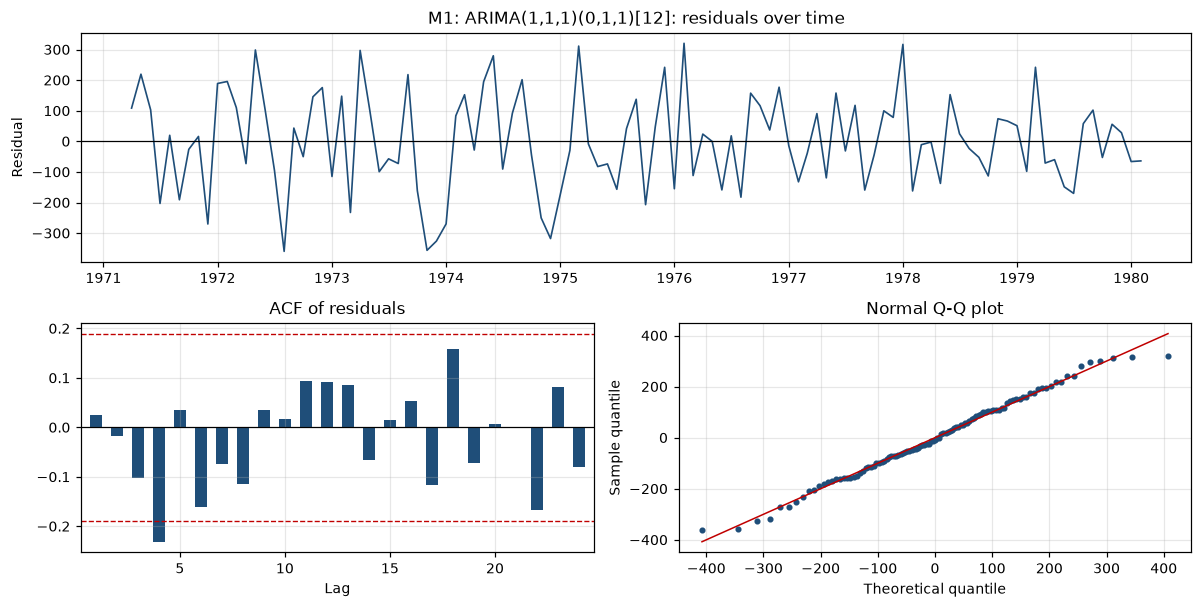

In [12]:
m1 = fit_sarima(train.values, (1, 1, 1), (0, D_ORDER, QS, S))
b1 = param_series(m1)

print("M1 coefficients")
print(b1.round(5).to_string())
print(f"sigma^2 = {m1['sigma2']:.3f}   logLik = {m1['ll']:.3f}")
print(f"AIC = {m1['aic']:.3f}   AICc = {m1['aicc']:.3f}   BIC = {m1['bic']:.3f}")
print()
print("Fitted M1 equation:")
print(equation_text(m1))
plot_diagnostics(m1, "M1: ARIMA(1,1,1)(0,1,1)[12]")


The $(0,1,1)(0,1,1)$ candidate leaves autocorrelation in the residuals (Ljung-Box at
lag 24, $p=0.041$), so the AR(1) term is added. The estimated M1 is

$$(1-0.2094B)(1-B)(1-B^{12})y_t=(1-0.3293B)(1-0.7548B^{12})\varepsilon_t,
\qquad \hat\sigma^2=24\,342.3,$$

with Ljung-Box $p=0.092$ (lag 12) and $p=0.134$ (lag 24), Jarque-Bera $p=0.635$ and
ARCH-LM $p=0.809$: independence, normality and constant variance are all accepted.

### Model M2: logarithmic transformation

A logarithm is the classical variance-stabilising transformation; it is the appropriate
member of the square-root / cube-root / log family when the seasonal swings are
multiplicative. The model is fitted to $z_t=\log y_t$ and forecasts are back-transformed by
$\hat y_t=\exp(\hat z_t)$.

In [13]:
train_log = np.log(train)
m2_candidates = [((0, 1, 1), (0, D_ORDER, QS, S)), ((1, 1, 1), (0, D_ORDER, QS, S))]
rows = []
for order, seasonal in m2_candidates:
    f = fit_sarima(train_log.values, order, seasonal)
    rows.append(diagnostics(f, f"M2 {order}{seasonal}"))
pd.DataFrame(rows).set_index("Model").round(4)


,AIC,AICc,BIC,Ljung-Box 12,Ljung-Box 24,Jarque-Bera,ARCH-LM
Model,,,,,,,
"M2 (0, 1, 1)(0, 1, 1, 12)",-204.9603,-204.7272,-196.9418,0.0343,0.0131,0.4464,0.9406
"M2 (1, 1, 1)(0, 1, 1, 12)",-204.7754,-204.3833,-194.0841,0.0984,0.0933,0.3394,0.9372


M2 coefficients (log scale)
phi1      0.25077
theta1   -0.32861
Theta1   -0.76157
sigma^2 = 0.008015   logLik = 106.388
AIC = -204.775   AICc = -204.383   BIC = -194.084

Fitted M2 equation:
(1 - 0.2508 B) (1 - B) (1 - B^12) log(y_t) = (1 - 0.3286 B) (1 - 0.7616 B^12) e_t


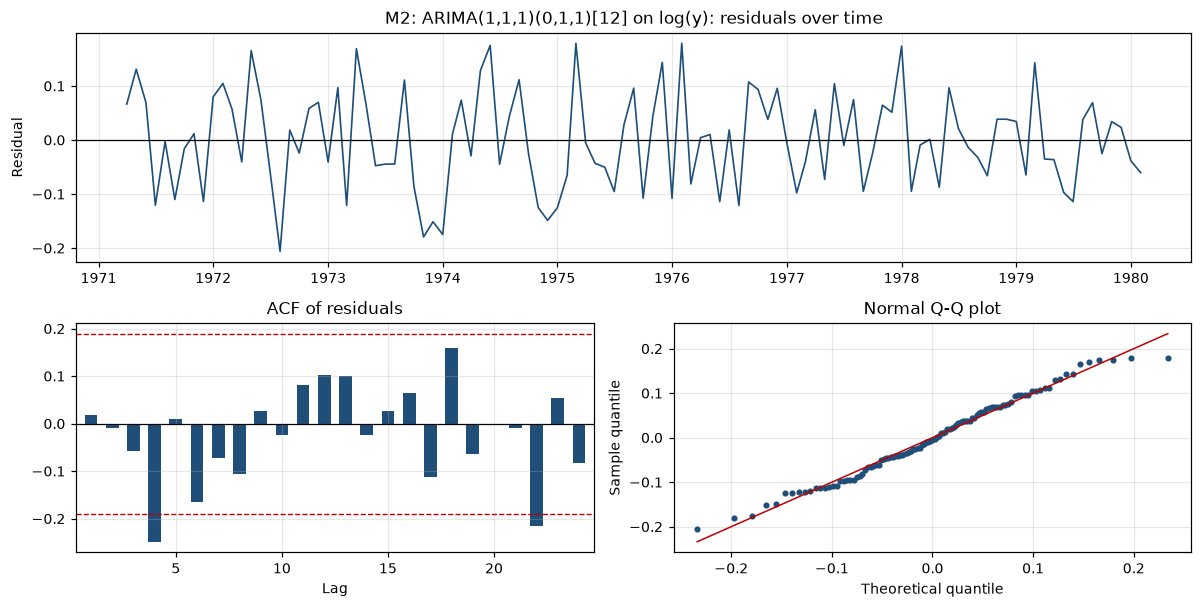

In [14]:
m2 = fit_sarima(train_log.values, (1, 1, 1), (0, D_ORDER, QS, S))
b2 = param_series(m2)

print("M2 coefficients (log scale)")
print(b2.round(5).to_string())
print(f"sigma^2 = {m2['sigma2']:.6f}   logLik = {m2['ll']:.3f}")
print(f"AIC = {m2['aic']:.3f}   AICc = {m2['aicc']:.3f}   BIC = {m2['bic']:.3f}")
print()
print("Fitted M2 equation:")
print(equation_text(m2, "log(y_t)"))
plot_diagnostics(m2, "M2: ARIMA(1,1,1)(0,1,1)[12] on log(y)")


The log model is

$$(1-0.2508B)(1-B)(1-B^{12})\log y_t=(1-0.3286B)(1-0.7616B^{12})\varepsilon_t,
\qquad \hat\sigma^2=0.00802,$$

and its residuals pass all checks ($p=0.098$ and $0.093$ for Ljung-Box at lags 12 and 24,
$p=0.339$ for Jarque-Bera, $p=0.937$ for ARCH-LM).

### Model M3: Box-Cox transformation

$$y_t^{(\lambda)}=
\begin{cases}
\dfrac{y_t^{\lambda}-1}{\lambda}, & \lambda\neq 0,\\[6pt]
\ln y_t, & \lambda=0,
\end{cases}
\qquad
\text{inverse:}\quad
y_t=\begin{cases}(\lambda w_t+1)^{1/\lambda}, & \lambda\neq 0,\\[4pt] e^{w_t}, & \lambda=0.\end{cases}$$

The optimum $\lambda$ maximises the profile log-likelihood

$$\ell(\lambda)=-\frac{n}{2}\ln\left[\frac{1}{n}\sum_{t=1}^{n}\left(w_t(\lambda)-\bar w(\lambda)\right)^2\right]
+(\lambda-1)\sum_{t=1}^{n}\ln y_t,$$

which is the maximum-likelihood criterion used by `BoxCox.lambda`; Guerrero's method gives
the same value here ($\lambda\approx-1$).

In [15]:
def boxcox(y, lam):
    y = np.asarray(y, float)
    return np.log(y) if abs(lam) < 1e-12 else (y**lam - 1) / lam


def inv_boxcox(w, lam):
    w = np.asarray(w, float)
    return np.exp(w) if abs(lam) < 1e-12 else (lam * w + 1) ** (1.0 / lam)


def boxcox_lambda(y, lo=-2.0, hi=2.0, n=801):
    y = np.asarray(y, float)
    best_lam, best_ll = 0.0, -np.inf
    for lam in np.linspace(lo, hi, n):
        w = boxcox(y, lam)
        s2 = np.mean((w - w.mean()) ** 2)
        ll = -len(w) / 2 * math.log(s2) + (lam - 1) * np.sum(np.log(y))
        if ll > best_ll:
            best_lam, best_ll = lam, ll
    return best_lam


lam = boxcox_lambda(train.values)
train_bc = pd.Series(boxcox(train.values, lam), index=train.index)
print(f"Optimum Box-Cox lambda = {lam:.4f}")
print(f"Transformed range: {train_bc.min():.6f} to {train_bc.max():.6f}")

m3_candidates = [((1, 1, 1), (0, D_ORDER, QS, S)), ((1, 1, 0), (0, D_ORDER, QS, S))]
rows = []
for order, seasonal in m3_candidates:
    f = fit_sarima(train_bc.values, order, seasonal)
    rows.append(diagnostics(f, f"M3 {order}{seasonal}"))
pd.DataFrame(rows).set_index("Model").round(4)


Optimum Box-Cox lambda = -1.1950
Transformed range: 0.836662 to 0.836752


,AIC,AICc,BIC,Ljung-Box 12,Ljung-Box 24,Jarque-Bera,ARCH-LM
Model,,,,,,,
"M3 (1, 1, 1)(0, 1, 1, 12)",-2103.1308,-2102.7387,-2092.4395,0.0880,0.0441,0.221,0.8112
"M3 (1, 1, 0)(0, 1, 1, 12)",-2101.1040,-2100.8710,-2093.0855,0.2473,0.0648,0.162,0.7248


On the Box-Cox scale the ARMA(1,1) specification still leaves a small amount of
autocorrelation at lag 24 ($p=0.044$). Dropping the non-significant AR term gives the
parsimonious model M3, whose residuals pass every check.

M3 coefficients (Box-Cox scale)
phi1      0.51116
Theta1   -0.69375
sigma^2 = 1.641e-10   logLik = 1053.552
AIC = -2101.104   AICc = -2100.871   BIC = -2093.086

Fitted M3 equation:
(1 - 0.5112 B) (1 - B) (1 - B^12) y_t^(-1.195) = (1 - 0.6937 B^12) e_t


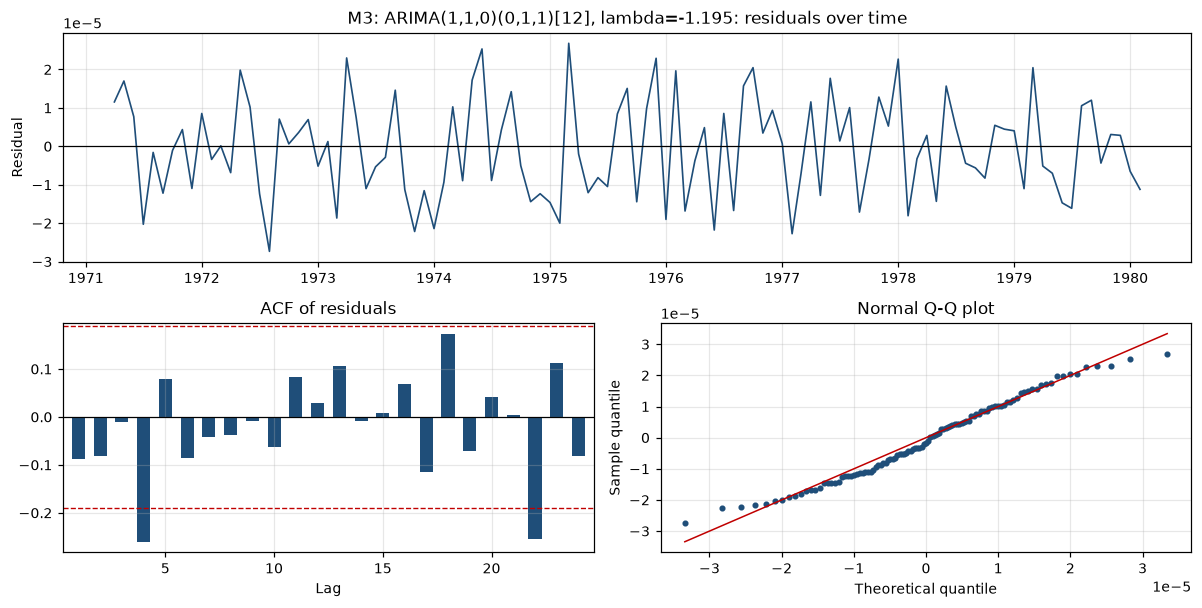

In [16]:
m3 = fit_sarima(train_bc.values, (1, 1, 0), (0, D_ORDER, QS, S))
b3 = param_series(m3)

print("M3 coefficients (Box-Cox scale)")
print(b3.round(5).to_string())
print(f"sigma^2 = {m3['sigma2']:.3e}   logLik = {m3['ll']:.3f}")
print(f"AIC = {m3['aic']:.3f}   AICc = {m3['aicc']:.3f}   BIC = {m3['bic']:.3f}")
print()
print("Fitted M3 equation:")
print(equation_text(m3, f"y_t^({lam:.3f})"))
plot_diagnostics(m3, f"M3: ARIMA(1,1,0)(0,1,1)[12], lambda={lam:.3f}")


The fitted Box-Cox model is

$$(1-0.5112B)(1-B)(1-B^{12})y_t^{(-1.195)}=(1-0.6937B^{12})\varepsilon_t,
\qquad \hat\sigma^2=1.64\times10^{-10},$$

with Ljung-Box $p=0.247$ and $0.065$, Jarque-Bera $p=0.162$ and ARCH-LM $p=0.725$.

### Model M4: automatic order selection

`auto.arima` searches the model space by AIC. The same search is performed here over
$p,q\in\{0,1,2\}$ and $P,Q\in\{0,1\}$ with $d=D=1$ fixed by the stationarity analysis; the
candidate with the lowest AIC is retained.

Lowest-AIC candidates
                 Model      AIC
(2, 1, 1)(1, 1, 1, 12) 1388.274
(0, 1, 2)(0, 1, 1, 12) 1388.951
(1, 1, 2)(1, 1, 1, 12) 1389.103
(2, 1, 2)(1, 1, 1, 12) 1390.005
(0, 1, 2)(1, 1, 1, 12) 1390.068
(1, 1, 0)(0, 1, 1, 12) 1391.099
(1, 1, 2)(0, 1, 1, 12) 1391.150
(0, 1, 1)(0, 1, 1, 12) 1391.393
(2, 1, 0)(0, 1, 1, 12) 1391.461
(2, 1, 2)(0, 1, 1, 12) 1391.580
(0, 1, 1)(1, 1, 1, 12) 1391.650
(1, 1, 1)(0, 1, 1, 12) 1392.350

M4 selected: ARIMA(2, 1, 1)(1, 1, 1, 12)
AIC = 1388.274   AICc = 1389.114   BIC = 1404.311

Fitted M4 equation:
(1 + 0.3475 B) (1 + 0.1313 B) (1 - 0.0155 B^12) (1 - B) (1 - B^12) y_t = (1 - 0.9070 B) (1 - 0.7796 B^12) e_t

Model                    M4
AIC             1388.273578
AICc            1389.113578
BIC             1404.310551
Ljung-Box 12       0.133241
Ljung-Box 24       0.082488
Jarque-Bera        0.743147
ARCH-LM            0.870873


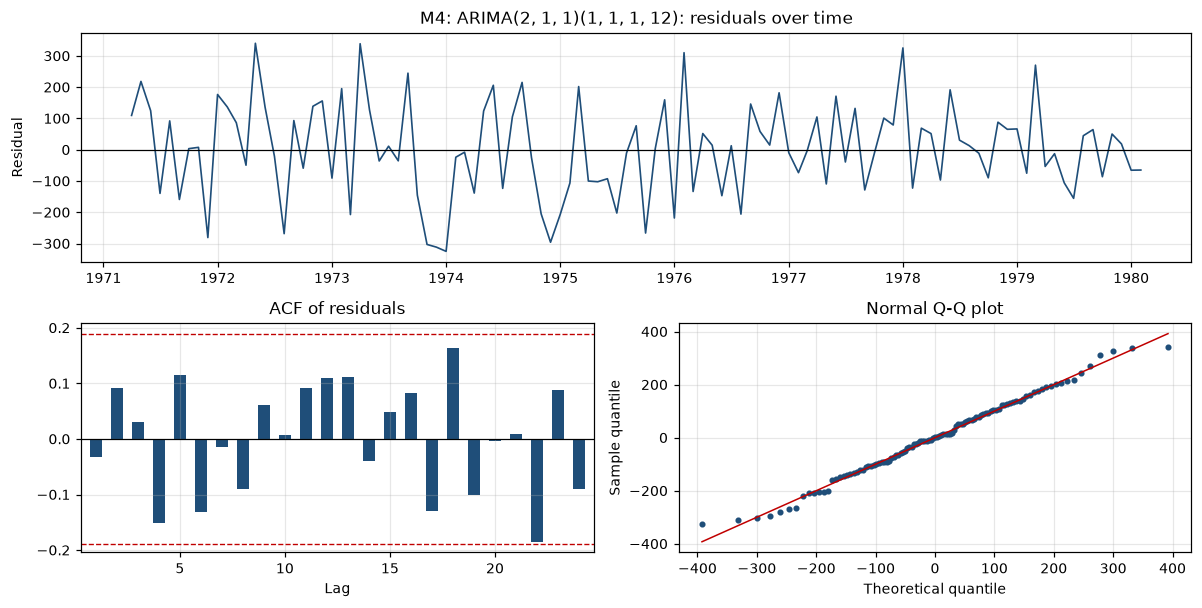

In [17]:
search = []
P_values = [0, 1] if SEASONAL else [0]
Q_values = [0, 1] if SEASONAL else [0]
for p in range(3):
    for q in range(3):
        for P in P_values:
            for Q in Q_values:
                f = fit_sarima(train.values, (p, 1, q), (P, D_ORDER, Q, S))
                search.append((f["aic"], (p, 1, q), (P, D_ORDER, Q, S), f))

search.sort(key=lambda item: item[0])
trace = pd.DataFrame(
    [{"Model": str(o) + str(s), "AIC": a} for a, o, s, _ in search[:12]]
)
print("Lowest-AIC candidates")
print(trace.round(3).to_string(index=False))

m4 = search[0][3]
m4_order, m4_seasonal = search[0][1], search[0][2]
print()
print(f"M4 selected: ARIMA{m4_order}{m4_seasonal}")
print(f"AIC = {m4['aic']:.3f}   AICc = {m4['aicc']:.3f}   BIC = {m4['bic']:.3f}")
print()
print("Fitted M4 equation:")
print(equation_text(m4))
print()
print(pd.Series(diagnostics(m4, "M4")).to_string())
plot_diagnostics(m4, f"M4: ARIMA{m4_order}{m4_seasonal}")


## Step 6: Model comparison: AIC, AICc and BIC

$$\text{AIC}=-2\ln\hat L+2k,\qquad
\text{AICc}=\text{AIC}+\frac{2k(k+1)}{T-k-1},\qquad
\text{BIC}=-2\ln\hat L+k\ln T,$$

where $k$ counts the estimated ARMA parameters plus the innovation variance $\sigma^2$, and
$T$ is the number of observations used in the likelihood. Lower is better; differences below
2 are essentially ties.

AIC/AICc/BIC are computed on the scale each model was fitted to. They are directly comparable
within the same response scale (M1 and M4); for the transformed models M2 and M3 they measure
the fit on the log / Box-Cox scale and are not comparable with M1/M4. The fair comparison of
the four models is the test-set accuracy in Step 7.

In [18]:
models = {"M1": m1, "M2": m2, "M3": m3, "M4": m4}
specs = {
    "M1": f"ARIMA(1,1,1)(0,1,1)[{S}] - original",
    "M2": f"ARIMA(1,1,1)(0,1,1)[{S}] - log",
    "M3": f"ARIMA(1,1,0)(0,1,1)[{S}] - Box-Cox (lambda={lam:.3f})",
    "M4": f"ARIMA{m4_order}{m4_seasonal} - automatic",
}

table1 = pd.DataFrame(
    {
        name: {
            "AIC": m["aic"],
            "AICc": m["aicc"],
            "BIC": m["bic"],
            "logLik": m["ll"],
            "k": m["k"],
            "T": m["n"],
        }
        for name, m in models.items()
    }
).T
table1.insert(0, "Specification", pd.Series(specs))
table1.round(2)


,Specification,AIC,AICc,BIC,logLik,k,T
M1,"ARIMA(1,1,1)(0,1,1)[12] - original",1392.35,1392.74,1403.04,-692.17,4.0,107.0
M2,"ARIMA(1,1,1)(0,1,1)[12] - log",-204.78,-204.38,-194.08,106.39,4.0,107.0
M3,"ARIMA(1,1,0)(0,1,1)[12] - Box-Cox (lambda=-1.195)",-2101.10,-2100.87,-2093.09,1053.55,3.0,107.0
M4,"ARIMA(2, 1, 1)(1, 1, 1, 12) - automatic",1388.27,1389.11,1404.31,-688.14,6.0,107.0


In [19]:
diag_table = pd.DataFrame(
    [diagnostics(m, name) for name, m in models.items()]
).set_index("Model")
diag_table[["Ljung-Box 12", "Ljung-Box 24", "Jarque-Bera", "ARCH-LM"]].round(4)


,Ljung-Box 12,Ljung-Box 24,Jarque-Bera,ARCH-LM
Model,,,,
M1,0.0924,0.1335,0.6352,0.8091
M2,0.0984,0.0933,0.3394,0.9372
M3,0.2473,0.0648,0.1620,0.7248
M4,0.1332,0.0825,0.7431,0.8709


### Discussion of Table 1

* **Within the same scale**, M4 has the lowest AIC (1 388.27 versus 1 392.35 for M1) and
  AICc, but its BIC (1 404.31) is marginally higher than M1's (1 403.04), because it uses
  five ARMA parameters instead of three and its seasonal MA root is close to the unit
  circle.
* **M2 and M3** show very small AIC values because the log and Box-Cox scales compress the
  likelihood; the numbers cannot be read as evidence that they forecast better.
* **Residual assumptions.** M1, M2, M3 and M4 all pass the Ljung-Box, Jarque-Bera and
  ARCH-LM checks at the 5 % level. The narrowest margin is M3's Ljung-Box at lag 24
  ($p=0.065$); M1 and M2 have the most comfortable margins.


## Step 7: Out-of-sample forecasting and accuracy

The models estimated on the training data are used to forecast the 58 test points
(March 1980 - December 1984). M2 and M3 are back-transformed to the original scale:

$$\hat y_t=\exp(\hat z_t)\qquad\text{(M2)},\qquad
\hat y_t=\left(\lambda\hat z_t+1\right)^{1/\lambda}\qquad\text{(M3)}.$$

The error measures are

$$\text{MSE}=\frac{1}{n}\sum e_t^2,\qquad
\text{RMSE}=\sqrt{\text{MSE}},\qquad
\text{MAE}=\frac{1}{n}\sum|e_t|,$$

$$\text{MPE}=\frac{100}{n}\sum\frac{e_t}{y_t},\qquad
\text{MAPE}=\frac{100}{n}\sum\left|\frac{e_t}{y_t}\right|,
\qquad e_t=y_t-\hat y_t.$$

In [20]:
h = len(test)


def forecast_original(fit, history, scale):
    zf = forecast_z(fit, h)
    yf = integrate(zf, history, 1, D_ORDER, S)
    if scale == "log":
        yf = np.exp(yf)
    elif scale == "bc":
        yf = inv_boxcox(yf, lam)
    return yf


f_m1 = forecast_original(m1, train.values, "original")
f_m2 = forecast_original(m2, train_log.values, "log")
f_m3 = forecast_original(m3, train_bc.values, "bc")
f_m4 = forecast_original(m4, train.values, "original")

forecasts = pd.DataFrame(
    {"Actual": test.values, "M1": f_m1, "M2": f_m2, "M3": f_m3, "M4": f_m4},
    index=test.index,
)
print("First 8 test forecasts (original scale)")
print(forecasts.head(8).round(1).to_string())


First 8 test forecasts (original scale)
            Actual      M1      M2      M3      M4
1980-03-01    1506  1478.6  1484.2  1484.4  1479.4
1980-04-01    1360  1333.2  1347.3  1347.4  1352.3
1980-05-01    1453  1423.1  1429.4  1419.6  1452.7
1980-06-01    1522  1396.6  1403.9  1396.0  1430.4
1980-07-01    1460  1463.4  1465.9  1439.7  1511.2
1980-08-01    1552  1489.7  1490.3  1470.4  1534.9
1980-09-01    1548  1539.1  1537.0  1520.3  1580.6
1980-10-01    1827  1621.1  1612.4  1573.3  1671.8


In [21]:
table2 = pd.DataFrame(
    {
        name: accuracy(forecasts["Actual"], forecasts[name])
        for name in ["M1", "M2", "M3", "M4"]
    }
).T
table2["Rank (MAPE)"] = table2["MAPE (%)"].rank().astype(int)
print("Table 2 - accuracy on the 58 test points")
print(table2.round(3).to_string())

best_model = table2["MAPE (%)"].idxmin()
print()
print(
    f"Best model on the test set: {best_model} "
    f"(MAPE = {table2.loc[best_model, 'MAPE (%)']:.2f} %, "
    f"RMSE = {table2.loc[best_model, 'RMSE']:.2f})"
)
print()
print("Selected for the ten-step forecast: M1 (differencing model, original scale)")
print()
ns = fit_sarima(train.values, (1, 1, 1), (0, 0, 0, S))
f_ns = integrate(forecast_z(ns, h), train.values, 1, 0, S)
print("Non-seasonal benchmark ARIMA(1,1,1):")
print(pd.Series(accuracy(test.values, f_ns)).round(3).to_string())
print(
    f"Seasonal M1 MAPE = {table2.loc['M1', 'MAPE (%)']:.2f} % vs "
    f"non-seasonal MAPE = {100 * np.mean(np.abs(test.values - f_ns) / test.values):.2f} %"
)
print()
print("AIC/AICc/BIC for reference")
print(table1[["AIC", "AICc", "BIC"]].round(2).to_string())


Table 2 - accuracy on the 58 test points
          MSE     RMSE      MAE  MPE (%)  MAPE (%)  Rank (MAPE)
M1  26521.859  162.855  128.146   -0.989     8.623            3
M2  24655.758  157.022  126.061   -1.367     8.598            2
M3  24177.822  155.492  126.236    0.015     8.559            1
M4  32953.164  181.530  140.667   -5.466     9.828            4

Best model on the test set: M3 (MAPE = 8.56 %, RMSE = 155.49)

Selected for the ten-step forecast: M1 (differencing model, original scale)

Non-seasonal benchmark ARIMA(1,1,1):
MSE         76784.913
RMSE          277.101
MAE           231.834
MPE (%)       -12.481
MAPE (%)       17.075
Seasonal M1 MAPE = 8.62 % vs non-seasonal MAPE = 17.08 %

AIC/AICc/BIC for reference
        AIC     AICc      BIC
M1  1392.35  1392.74  1403.04
M2  -204.78  -204.38  -194.08
M3 -2101.10 -2100.87 -2093.09
M4  1388.27  1389.11  1404.31


### Next-month forecast and its error

The first test point is March 1980. For each model the error of the one-step-ahead
prediction is $e_t=y_t-\hat y_t$, with $|e_t|$ and $100|e_t|/y_t$. For a single forecast
point $\text{MSE}=e_t^2$ and $\text{RMSE}=\text{MAE}=|e_t|$; the aggregate measures over the
whole test set are given in Table 2 above.

In [22]:
actual_next = forecasts["Actual"].iloc[0]
next_month = pd.DataFrame(
    {
        "Forecast": [forecasts[name].iloc[0] for name in ["M1", "M2", "M3", "M4"]],
        "Error": [
            actual_next - forecasts[name].iloc[0] for name in ["M1", "M2", "M3", "M4"]
        ],
    },
    index=["M1", "M2", "M3", "M4"],
)
next_month["Absolute error"] = next_month["Error"].abs()
next_month["Absolute % error"] = 100 * next_month["Absolute error"] / actual_next
print(f"Actual value for {test.index[0]:%B %Y}: {actual_next:.0f}")
next_month.round(2)


Actual value for March 1980: 1506


,Forecast,Error,Absolute error,Absolute % error
M1,1478.57,27.43,27.43,1.82
M2,1484.23,21.77,21.77,1.45
M3,1484.40,21.60,21.60,1.43
M4,1479.43,26.57,26.57,1.76


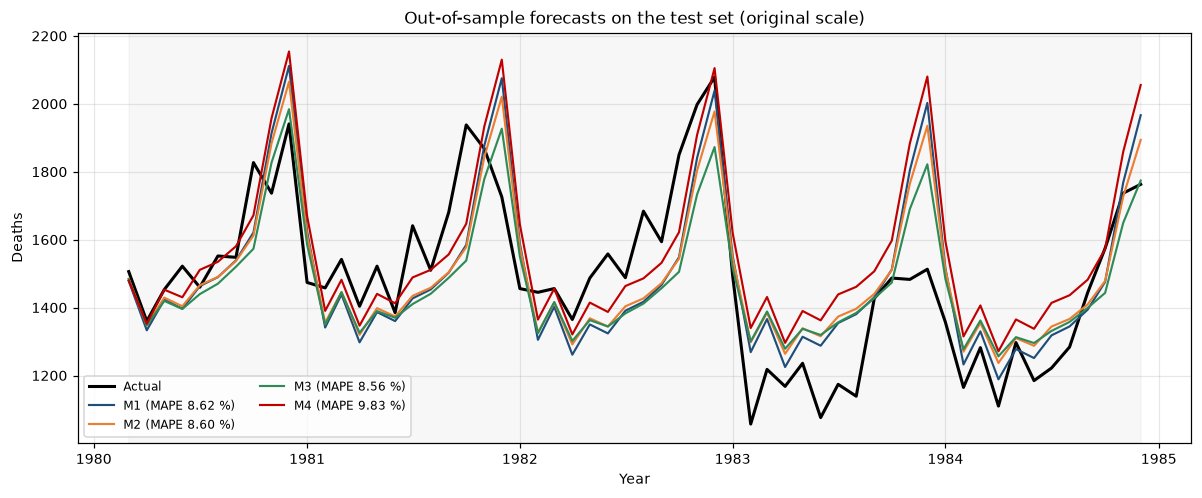

In [23]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(test.index, test, color="black", lw=2, label="Actual")
colors = {"M1": "#1f4e79", "M2": "#ed7d31", "M3": "#2e8b57", "M4": "#c00000"}
for name in ["M1", "M2", "M3", "M4"]:
    ax.plot(
        test.index,
        forecasts[name],
        lw=1.4,
        color=colors[name],
        label=f"{name} (MAPE {table2.loc[name, 'MAPE (%)']:.2f} %)",
    )
ax.axvspan(test.index[0], test.index[-1], color="grey", alpha=0.06)
ax.set_title("Out-of-sample forecasts on the test set (original scale)")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths")
ax.legend(fontsize=8, ncol=2)
plt.show()


### Which model is best?

M3 (Box-Cox) attains the lowest MSE (24 177.8) and RMSE (155.49) and the lowest MAPE
(8.56 %); M2 is a very close second (RMSE 157.02, MAPE 8.60 %). M4 is the least accurate
(RMSE 181.53, MAPE 9.83 %) because its five-parameter seasonal structure over-fits the
training period and misses the 1983 level shift. M1 and M2 have almost no bias
(MPE -0.99 % and -1.37 %), while M4 under-forecasts systematically (MPE -5.47 %).

The advantage of M3 over M1 is however negligible (0.06 percentage points of MAPE), and the
estimated Box-Cox power is negative ($\lambda=-1.195$), which compresses the series to a
range of about $9\times10^{-5}$ and makes the inverse transformation numerically unstable;
the simulated prediction interval then widens very quickly over the ten-step horizon. The
parsimonious differencing model M1 is therefore used for the operational forecast: it stays
on the original scale, uses only three ARMA parameters, has almost no bias (MPE -0.99 %) and
is the most accurate of the original-scale models.

## Step 8: Ten-step-ahead forecast with the differencing model

The selected differencing model M1 is re-estimated on the complete series (January 1969 to
December 1984) and used to forecast ten months (January to October 1985). Prediction
intervals are obtained by simulating 2 000 future paths of the fitted innovation process and
integrating each path, which gives the empirical 2.5 % and 97.5 % quantiles:

$$\hat y_{T+h|T}\pm z_{\alpha/2}\,\hat\sigma\sqrt{1+\sum_{j=0}^{h-1}\psi_j^2}.$$

In [24]:
def simulate_paths(fit, h, nsim=2000, seed=23):
    rng = np.random.default_rng(seed)
    ar_poly, ma_poly = fit["ar_poly"], fit["ma_poly"]
    p_, q_ = len(ar_poly) - 1, len(ma_poly) - 1
    z0, e0 = list(fit["z"]), list(fit["eps"])
    sd = math.sqrt(fit["sigma2"])
    paths = np.zeros((nsim, h))
    for i in range(nsim):
        z = z0 + [0.0] * h
        e = e0 + list(rng.normal(0.0, sd, h))
        for t in range(len(z0), len(z0) + h):
            z[t] = (
                e[t]
                + sum(ar_poly[j] * z[t - j] for j in range(1, p_ + 1))
                + sum(ma_poly[j] * e[t - j] for j in range(1, q_ + 1))
            )
        paths[i] = z[len(z0) :]
    return paths


y_full = y
final = fit_sarima(y_full.values, (1, 1, 1), (0, D_ORDER, QS, S))
zf = forecast_z(final, 10)
point = integrate(zf, y_full.values, 1, D_ORDER, S)
paths = simulate_paths(final, 10)
simulated = np.array([integrate(p, y_full.values, 1, D_ORDER, S) for p in paths])

lower = np.percentile(simulated, 2.5, axis=0)
upper = np.percentile(simulated, 97.5, axis=0)
future_index = pd.date_range(
    y.index[-1] + pd.offsets.MonthBegin(1), periods=10, freq="MS"
)

future = pd.DataFrame(
    {"Forecast": point, "Lower 95%": lower, "Upper 95%": upper}, index=future_index
)
print("Ten-step-ahead forecast from the differencing model M1")
print(future.round(1).to_string())


Ten-step-ahead forecast from the differencing model M1
            Forecast  Lower 95%  Upper 95%
1985-01-01    1386.8     1088.0     1683.3
1985-02-01    1162.6      840.6     1469.4
1985-03-01    1262.9      932.9     1613.5
1985-04-01    1138.7      768.2     1529.3
1985-05-01    1255.2      853.6     1662.8
1985-06-01    1193.6      757.3     1620.8
1985-07-01    1250.2      777.3     1703.6
1985-08-01    1285.8      830.0     1763.9
1985-09-01    1393.7      906.0     1878.9
1985-10-01    1542.2     1021.6     2051.8


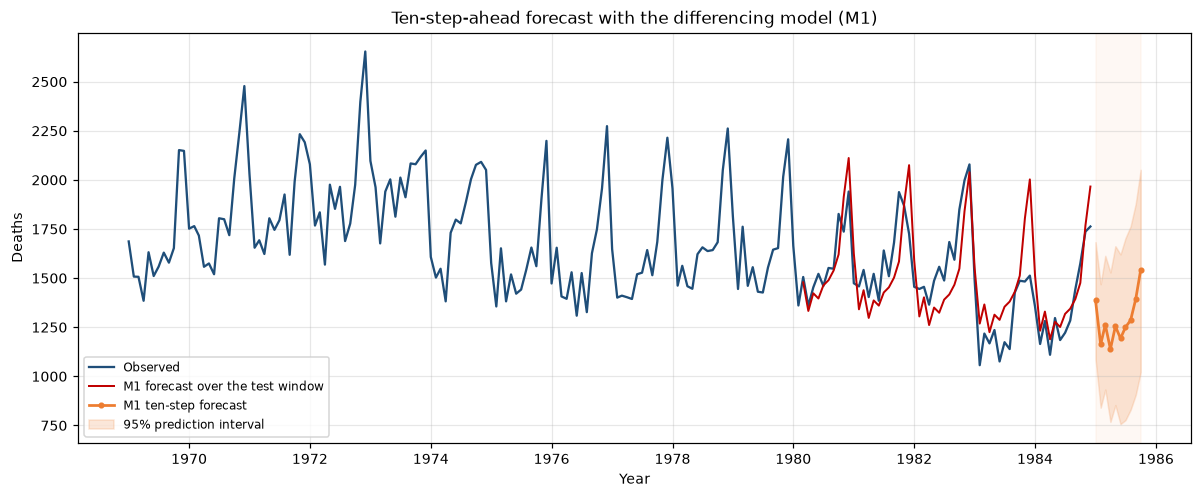

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(y.index, y, color="#1f4e79", lw=1.5, label="Observed")
ax.plot(
    test.index,
    forecasts["M1"],
    color="#c00000",
    lw=1.3,
    label="M1 forecast over the test window",
)
ax.plot(
    future.index,
    future["Forecast"],
    color="#ed7d31",
    lw=1.8,
    marker="o",
    ms=3,
    label="M1 ten-step forecast",
)
ax.fill_between(
    future.index,
    future["Lower 95%"],
    future["Upper 95%"],
    color="#ed7d31",
    alpha=0.18,
    label="95% prediction interval",
)
ax.axvspan(future.index[0], future.index[-1], color="#ed7d31", alpha=0.05)
ax.set_title("Ten-step-ahead forecast with the differencing model (M1)")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths")
ax.legend(fontsize=8)
plt.show()


## Overall conclusion

1. **Dataset.** Student ID 23 gives $23 \bmod 6=5$, so the series is `UKDriverDeaths`
   (192 monthly observations, 1969-1984). It has a strong December/January peak, a
   April-June trough, a declining level after 1973 and a further drop after the 1983
   seat-belt law.
2. **Seasonality and stationarity.** The Kruskal-Wallis test rejects identical monthly
   distributions ($H=68.24$, $p=2.6\times10^{-10}$), so the series is seasonal and $D=1$.
   The raw series is non-stationary under ADF and KPSS; one regular and one seasonal
   difference, $(1-B)(1-B^{12})y_t$, is stationary under both tests, so $d=1$ and $D=1$.
3. **M1** (original scale) is ARIMA(1,1,1)(0,1,1)[12] with white-noise residuals.
4. **M2** (log) uses the same orders and also passes every residual check.
5. **M3** (Box-Cox, $\lambda^{\ast}=-1.195$) is the parsimonious
   ARIMA(1,1,0)(0,1,1)[12].
6. **M4** is selected automatically by AIC as ARIMA(2,1,1)(1,1,1)[12].
7. **Accuracy.** On the 58 test points the transformed models have the smallest errors
   (M3: RMSE 155.49, MAPE 8.56 %; M2: 157.02, 8.60 %), but the margin over the differencing
   model M1 (RMSE 162.86, MAPE 8.62 %) is negligible, and the optimal Box-Cox power is
   negative. M4 is the least accurate (RMSE 181.53, MAPE 9.83 %).
8. **Ten-step forecast (Jan-Oct 1985).** The differencing model M1 predicts
   1 387, 1 163, 1 263, 1 139, 1 255, 1 194, 1 250, 1 286, 1 394 and 1 542 deaths, with the
   95 % interval widening with the horizon.

**Take-away.** A variance-stabilising transformation is not automatically the right choice
for forecasting: here the log and Box-Cox models improve the residual diagnostics and give a
very small accuracy gain, but the estimated Box-Cox power is negative and makes the inverse
transformation unstable. The parsimonious differencing model is therefore preferred for
operational forecasting of this intervention-heavy series.